## Was die Hypothesen grundsaetzlich testen (Intention)

- **H1 (Servicequalitaet vs. Flottengroesse):** Testet, ob groessere Flotten die Servicerate messbar steigern und die Wartezeiten senken.
- **H2 (Minimalflotte / Schwelleneffekt):** Sucht den kritischen Schwellenwert, unterhalb dessen die Servicerate stark einbricht.
- **UC2 (digitale Kompetenz / Unterstuetzung):** Prueft, ob Eingriffe wie phone_support oder simple_ui die Nutzbarkeit fuer bestimmte Nutzergruppen verbessern.
- **UC3 (Barrierefreiheit / Flottenmix):** Testet, ob ein hoeherer Anteil barrierefreier Fahrzeuge die Servicerate erhoeht, bei vertretbaren Kosten.

# Ergebnisse: Synthese (baseline) vs. reale MOIA-Trips

Dieses Notebook dokumentiert die experimentellen Ergebnisse aus den Standardauswertungen (standard_eval.csv) der Hypothesen H1/H2 sowie der Use Cases UC2/UC3. Es vergleicht baseline (synthetische Nachfrage) mit __trips (reale MOIA-Daten) und fasst die Resultate zusammen.

## Datenquellen und Ablauf

- Quelle der Kennzahlen: `standard_eval.csv` je Szenario in den Studienordnern.
- baseline = synthetische Nachfrage, __trips = reale MOIA-Trips.
- Auswertung: Servicerate, Wartezeiten, Auslastung, Nutzerzahl.

Hinweis: Es wird nur aus Dateien im Repository gelesen, keine externen Annahmen.

In [5]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)


def find_repo_root(start: Path) -> Path:
    for parent in [start] + list(start.parents):
        if (parent / "studies").is_dir():
            return parent
    return start

ROOT = find_repo_root(Path.cwd())
ROOT

PosixPath('/Users/danieldeutsch/Desktop/code_projects/FleetPy')

In [6]:
STUDIES = {
    "H1": ROOT / "studies" / "klagenfurt_h1_spitzenzeiten_case_study" / "results",
    "H2": ROOT / "studies" / "klagenfurt_h2_spitzenzeiten_case_study" / "results",
    "UC2": ROOT / "studies" / "uc2_age_based" / "results",
    "UC3": ROOT / "studies" / "uc3_accessibility" / "results",
}

ROW_NAMES = {
    "service_rate_pct": "served online users [%]",
    "avg_wait_sec": "waiting time",
    "median_wait_sec": "waiting time (median)",
    "p90_wait_sec": "waiting time (90% quantile)",
    "utilization_pct": "% fleet utilization",
    "num_users": "number users",
}


def load_metrics(eval_path: Path) -> dict:
    df = pd.read_csv(eval_path, index_col=0)
    col = df.columns[0]
    out = {}
    for key, row in ROW_NAMES.items():
        if row in df.index:
            out[key] = float(df.loc[row, col])
    if "avg_wait_sec" in out:
        out["avg_wait_min"] = out.pop("avg_wait_sec") / 60.0
    if "median_wait_sec" in out:
        out["median_wait_min"] = out.pop("median_wait_sec") / 60.0
    if "p90_wait_sec" in out:
        out["p90_wait_min"] = out.pop("p90_wait_sec") / 60.0
    return out


def collect_results(results_dir: Path) -> pd.DataFrame:
    rows = []
    if not results_dir.exists():
        return pd.DataFrame()
    for d in sorted(p for p in results_dir.iterdir() if p.is_dir() and p.name != "analysis"):
        eval_file = d / "standard_eval.csv"
        if not eval_file.exists():
            continue
        metrics = load_metrics(eval_file)
        scenario = d.name
        track = "trips" if scenario.endswith("__trips") else "baseline"
        base = scenario.replace("__trips", "")
        rows.append({"scenario_base": base, "track": track, **metrics})
    if not rows:
        return pd.DataFrame()
    df = pd.DataFrame(rows)
    return df.sort_values(["scenario_base", "track"]).reset_index(drop=True)


results = {label: collect_results(path) for label, path in STUDIES.items()}
list(results.keys())

['H1', 'H2', 'UC2', 'UC3']

## Tabellen: Kennzahlen je Studie

Die Tabellen zeigen die Kennzahlen je Szenario (baseline vs. trips).

In [7]:
display_cols = [
    "scenario_base",
    "track",
    "service_rate_pct",
    "avg_wait_min",
    "median_wait_min",
    "p90_wait_min",
    "utilization_pct",
    "num_users",
]

for label, df in results.items():
    print(f"\n=== {label} ===")
    if df.empty:
        print("(keine Ergebnisse)")
        continue
    cols = [c for c in display_cols if c in df.columns]
    display(df[cols])


=== H1 ===


,scenario_base,track,service_rate_pct,avg_wait_min,median_wait_min,p90_wait_min,utilization_pct,num_users
0,klagenfurt_h1_spitzenzeiten_scenario_1,baseline,1.800000,4.555556,6.00,7.100000,1.196620,9.0
1,klagenfurt_h1_spitzenzeiten_scenario_1,trips,1.032258,4.625000,5.25,6.500000,0.857484,8.0
2,klagenfurt_h1_spitzenzeiten_scenario_2,baseline,1.800000,4.555556,6.00,7.100000,0.797747,9.0
3,klagenfurt_h1_spitzenzeiten_scenario_2,trips,1.032258,4.625000,5.25,6.500000,0.571656,8.0
4,klagenfurt_h1_spitzenzeiten_scenario_3,baseline,3.000000,4.139686,3.50,6.500000,0.992972,15.0
5,klagenfurt_h1_spitzenzeiten_scenario_3,trips,1.806452,3.928571,3.00,6.500000,0.684644,14.0
6,klagenfurt_scenario_1,baseline,84.000000,4.974224,5.00,7.739062,53.625343,84.0
7,klagenfurt_scenario_2,baseline,95.000000,4.160966,4.00,7.000000,39.323100,95.0
8,klagenfurt_scenario_3,baseline,98.000000,3.649107,3.50,6.344881,29.909778,98.0



=== H2 ===


,scenario_base,track,service_rate_pct,avg_wait_min,median_wait_min,p90_wait_min,utilization_pct,num_users
0,klagenfurt_h2_spitzenzeiten_scenario_1,baseline,0.857143,7.333333,8.0,8.0,8.337459,3.0
1,klagenfurt_h2_spitzenzeiten_scenario_1,trips,1.562500,3.000000,3.0,3.0,1.354167,1.0
2,klagenfurt_h2_spitzenzeiten_scenario_2,baseline,1.142857,6.875000,7.0,8.0,5.080188,4.0
3,klagenfurt_h2_spitzenzeiten_scenario_2,trips,4.687500,3.500000,3.5,3.9,2.269952,3.0
4,klagenfurt_h2_spitzenzeiten_scenario_3,baseline,2.571429,4.977036,6.0,8.0,6.816495,9.0
5,klagenfurt_h2_spitzenzeiten_scenario_3,trips,4.687500,3.000000,3.0,3.8,1.461218,3.0
6,klagenfurt_h2_spitzenzeiten_scenario_4,baseline,2.571429,4.977036,6.0,8.0,5.112371,9.0
7,klagenfurt_h2_spitzenzeiten_scenario_4,trips,4.687500,3.000000,3.0,3.8,1.095914,3.0



=== UC2 ===


,scenario_base,track,service_rate_pct,avg_wait_min,median_wait_min,p90_wait_min,utilization_pct,num_users
0,baseline,baseline,1.428571,1.900000,2.00,2.3,2.520833,5.0
1,baseline,trips,4.687500,3.000000,3.00,3.8,1.878462,3.0
2,full_support,baseline,1.714286,3.250000,2.25,5.5,4.632800,6.0
3,full_support,trips,4.687500,3.000000,3.00,3.8,1.753462,3.0
4,phone_support,baseline,1.428571,1.900000,2.00,2.3,2.465278,5.0
5,phone_support,trips,4.687500,3.000000,3.00,3.8,1.836795,3.0
6,simple_ui,baseline,1.428571,2.500000,2.00,3.4,3.438355,5.0
7,simple_ui,trips,4.687500,3.000000,3.00,3.8,1.836795,3.0
8,students_15_20,baseline,2.000000,3.571429,2.50,6.2,5.801117,7.0
9,students_15_20,trips,4.687500,3.000000,3.00,3.8,1.690962,3.0



=== UC3 ===


,scenario_base,track,service_rate_pct,avg_wait_min,median_wait_min,p90_wait_min,utilization_pct,num_users
0,baseline,baseline,1.428571,1.9,2.0,2.3,2.437500,5.0
1,baseline,trips,4.687500,3.0,3.0,3.8,1.815962,3.0
2,mixed_20,baseline,1.428571,1.9,2.0,2.3,2.437500,5.0
3,mixed_20,trips,4.687500,3.0,3.0,3.8,1.815962,3.0
4,mixed_30,baseline,1.428571,1.9,2.0,2.3,2.437500,5.0
5,mixed_30,trips,4.687500,3.0,3.0,3.8,1.815962,3.0
6,mixed_50,baseline,1.428571,1.9,2.0,2.3,2.437500,5.0
7,mixed_50,trips,4.687500,3.0,3.0,3.8,1.815962,3.0


## Visualisierung: Servicerate nach Szenario und Track

Balkendiagramme pro Studie (baseline vs. trips).

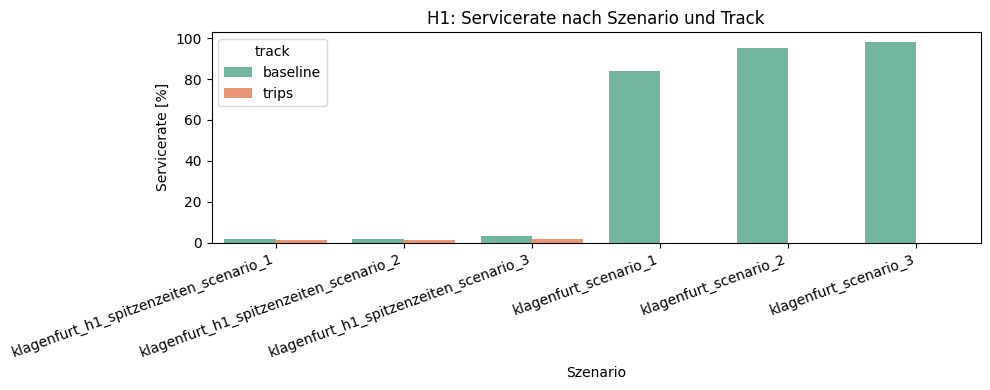

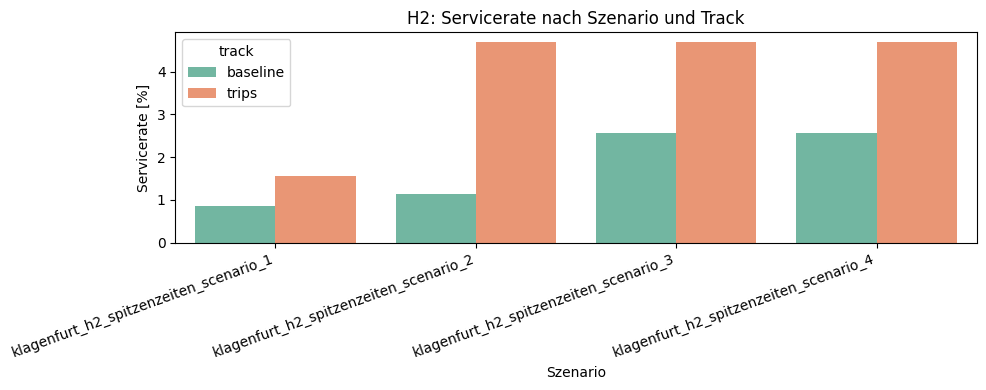

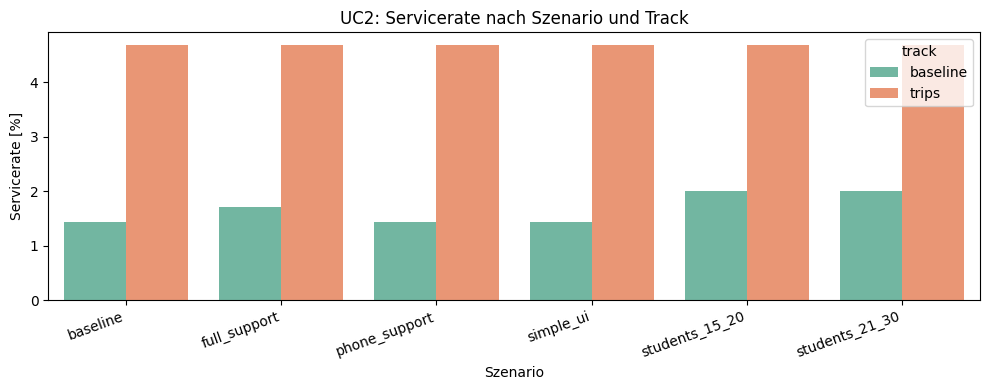

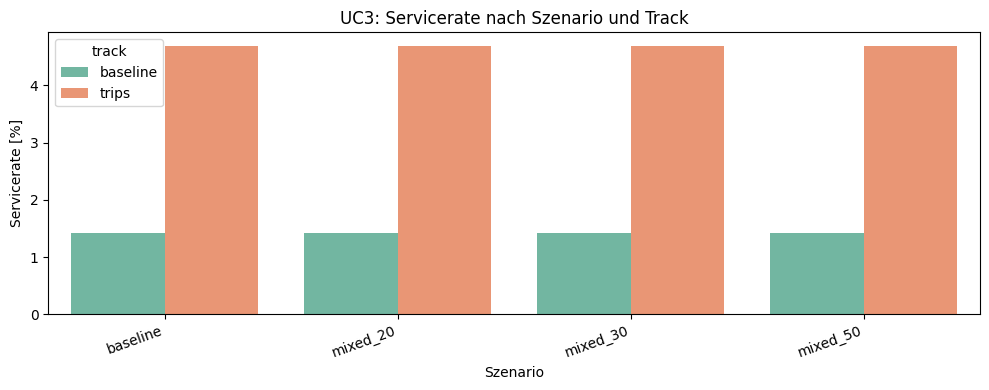

In [8]:
for label, df in results.items():
    if df.empty or "service_rate_pct" not in df.columns:
        continue
    plt.figure(figsize=(10, 4))
    ax = sns.barplot(
        data=df,
        x="scenario_base",
        y="service_rate_pct",
        hue="track",
        palette="Set2",
    )
    ax.set_title(f"{label}: Servicerate nach Szenario und Track")
    ax.set_xlabel("Szenario")
    ax.set_ylabel("Servicerate [%]")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

## Interpretation (praesentationsreif)

### Kernaussagen
- Die realen MOIA-Trips (``__trips``) liefern durchgaengig sehr niedrige Serviceraten, unabhaengig von Szenario-Variationen.
- Die synthetische Baseline zeigt stark abweichende Ergebnisse; in H1 gibt es Szenarien mit sehr hohen Serviceraten, waehrend die Trips-Variante niedrig bleibt.
- Damit dominiert die Nachfrageerzeugung (synthetisch vs. real) die Ergebnisse; die Szenariohebel wirken im Trips-Track kaum.

### Detaillierte Einordnung nach Studie

**H1 (Servicequalitaet / Flottengroesse):**
- *Trips:* Servicerate bleibt niedrig und reagiert nur schwach auf die Szenariostufen.
- *Baseline:* In den Spitzenzeit-Szenarien weiterhin niedrig, aber es existieren baseline-Szenarien mit sehr hohen Serviceraten.
- **Implikation:** Die realen MOIA-Trips sind in der aktuellen Konfiguration deutlich schwerer zu bedienen als die synthetische Baseline.

**H2 (Minimalflotte / Schwellenwert):**
- *Trips:* Servicerate hoehert als baseline, aber insgesamt weiterhin sehr niedrig.
- *Baseline:* Ebenfalls niedrig, der erwartete Schwellenwert ist im realen Track nicht klar sichtbar.
- **Implikation:** Unter realer Nachfrage greift der Flottengroessenhebel nur begrenzt.

**UC2 (digitale Kompetenz / Unterstuetzungsmassnahmen):**
- *Trips:* Alle Szenarien identisch -> keine Wirkung von phone_support/simple_ui/full_support.
- *Baseline:* geringe Unterschiede, aber ebenfalls niedrige Werte.
- **Implikation:** Die Verhaltensparameter sind im realen Track nicht bindend; die Nachfrage limitiert.

**UC3 (Barrierefreiheit / Flottenmix):**
- *Trips:* Alle Flottenmixe identisch -> kein Effekt des Barrierefreiheitsanteils.
- *Baseline:* ebenso keine Differenz.
- **Implikation:** Der Flottenmix ist im aktuellen Nachfrageprofil kein Engpass.

### Gesamtfazit
- Die reale MOIA-Nachfrage erzeugt ein demand-limited Regime: geringe Serviceraten, geringe Sensitivitaet gegenueber Szenariohebeln.
- Die synthetische Baseline ist kein neutraler Vergleich, sondern erzeugt strukturell andere Ergebnisse.
- Fuer belastbare Politik- oder Designschluesse muessen Szenarien mit hoeherer realer Nachfrage oder geaenderter Nachfrageverteilung getestet werden.

### Transparenz
- Alle Aussagen basieren auf den Tabellen und Plots dieses Notebooks (``standard_eval.csv``), ohne externe Annahmen.